**รายชื่อสมาชิก รหัสนักศึกษา และหน้าที่รับผิดชอบ**

| ชื่อ–สกุล | รหัสนักศึกษา | หน้าที่ |
|---|---|---|
| สิริภัท ธนสุขโสภณ | 6809540179 | ยังไม่กำหนด |
| ภณวรรชน์ โขงเขตต์ | 6809617282 | ยังไม่กำหนด |
| รมณ ประภาพรสุข | 6809617332 | ยังไม่กำหนด |
| วิรมณ มาเกิด | 6809617407 | ยังไม่กำหนด |
| อานัส บินเสะ | 6809617522 | ยังไม่กำหนด |
| ณพวุฒิ วิทยากุล | 6809681429 | ยังไม่กำหนด |
| ปาณิศรา แวงดิศร | 6809681452 | ยังไม่กำหนด |
| ศรัณย์วิชญ์ โพธิ์ชัย | 6809681478 | ยังไม่กำหนด |
| อานนท์ พูนสิน | 6809681494 | ยังไม่กำหนด |


# พยากรณ์จำนวนอุบัติเหตุเดือนหน้า
งานนี้เป็น **Regression** เพราะคำตอบเป็นจำนวน เช่น “ประมาณ 40 เหตุ”

**Pain point:** การจัดกำลังตรวจตราล่วงหน้าทำได้ยาก หากยังไม่ทราบว่าสายทางใดอาจมีจำนวนเหตุสูงในเดือนหน้า

**เป้าหมาย:** ช่วยวางแผนเฝ้าระวังบน 4 สายทางหลักในกรุงเทพฯ
**สิ่งที่จะทำ:** อ่านไฟล์ → เตรียมข้อมูล → ฝึก 3 โมเดล → เปรียบเทียบ → ทำนาย

เปิดโปรเจกต์นี้ แล้วเปิด Notebook ใน `notebooks/` และรันเซลล์จากบนลงล่าง ข้อมูลอยู่ใน `data/` และอ่านด้วย path ภายในโปรเจกต์

## 1. อ่านข้อมูล
ใช้ข้อมูลปี 2564–2569 เฉพาะกรุงเทพฯ ปี 2569 มีถึงเดือนตุลาคม
เก็บเฉพาะคอลัมน์ที่จำเป็น เพื่อลดข้อมูลที่ต้องอ่าน

ไฟล์ใน `data/` คัดไว้เฉพาะกรุงเทพฯ จากต้นฉบับกระทรวงคมนาคม เพื่อลดขนาดสำหรับแชร์ผ่าน GitHub โดยเก็บคอลัมน์และรายการกรุงเทพฯ เดิมไว้ครบ

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

pd.set_option("display.max_rows", 8)
pd.set_option("display.max_columns", 8)

In [2]:
# ใช้ path ภายในโปรเจกต์ จึงคัดลอกหรือ clone ไปเครื่องอื่นได้
project_dir = Path.cwd().resolve()
if (project_dir / "road-accident-forecast").is_dir():
    project_dir = project_dir / "road-accident-forecast"
if not (project_dir / "data").is_dir():
    project_dir = project_dir.parent  # กรณีรันจาก notebooks/
data_dir = project_dir / "data"
if not data_dir.is_dir():
    raise FileNotFoundError("เปิดโฟลเดอร์โปรเจกต์หรือ notebooks ก่อนรัน")
years = [2021, 2022, 2023, 2024, 2025, 2026]

In [3]:
# อ่านทีละปี และเปลี่ยนชื่อคอลัมน์ให้เขียนง่าย
frames = []
for year in years:
    table = pd.read_csv(data_dir / f"accident{year}.csv", dtype=str, encoding="utf-8-sig")
    table = table.loc[table["จังหวัด"].str.strip().eq("กรุงเทพมหานคร")].copy()
    table = table.drop_duplicates()  # ลบแถวที่เหมือนกันทุกช่อง
    table = table.rename(columns={"วันที่เกิดเหตุ": "date", "เวลา": "time",
        "หน่วยงาน": "agency", "รหัสสายทาง": "route_code"})
    if "ACC_CODE" not in table.columns:  # ปี 2569 ไม่มีรหัสเหตุ
        table["ACC_CODE"] = pd.NA
    table["year"] = year
    frames.append(table[["year", "date", "time", "agency", "route_code", "ACC_CODE"]])

data = pd.concat(frames, ignore_index=True)

In [4]:
# ดูเพียงตัวอย่าง 3 แถว
print("จำนวนรายการก่อนตรวจเพิ่มเติม:", len(data))
data.head(3)

จำนวนรายการก่อนตรวจเพิ่มเติม: 13569


,year,date,time,agency,route_code,ACC_CODE
0,2021,1/1/2021,2:00,กรมทางหลวง,338,3813107
1,2021,1/1/2021,11:00,กรมทางหลวง,9,3805748
2,2021,1/1/2021,19:00,กรมทางหลวง,304,5746608


## 2. เตรียมข้อมูล
ทำวันเวลาและชื่อสายทางให้ตรงกัน พักรายการที่รหัสเดียวกันแต่ข้อมูลขัดแย้ง
เรานับ “เหตุที่บันทึกหลังตรวจข้อมูล” ซึ่งอาจยังไม่ครบทุกเหตุจริง

In [5]:
# แต่ละปีบันทึกวันที่ไม่เหมือนกัน จึงแปลงแยกปี
# เก็บข้อความเดิม แล้วสร้างช่องวันที่ที่ Python ใช้คำนวณได้
data["date_text"] = data["date"]
data["date"] = pd.NaT
for year in years:
    rows = data["year"].eq(year)
    values = data.loc[rows, "date_text"]
    if year in [2024, 2025]:
        numbers = pd.to_numeric(values, errors="coerce")
        dates = pd.to_datetime(numbers, unit="D", origin="1899-12-30", errors="coerce")
    else:
        date_format = "%d/%m/%Y" if year == 2026 else "%m/%d/%Y"
        dates = pd.to_datetime(values, format=date_format, errors="coerce")
    data.loc[rows, "date"] = dates

data["date"] = pd.to_datetime(data["date"])

In [6]:
# วันที่ต้องอยู่ในปีของไฟล์ และต้องรู้ว่าสายทางใด
valid_date = data["date"].notna() & data["date"].dt.year.eq(data["year"])
data = data.loc[valid_date].dropna(subset=["agency", "route_code"]).copy()
data["agency"] = data["agency"].str.strip()
data["route_code"] = data["route_code"].str.strip()
data["route_id"] = data["agency"] + ":" + data["route_code"]

### 38 คอลัมน์ / 61 รหัส / 4 สายทาง ต่างกันอย่างไร?
- **38 คอลัมน์:** ประเภทข้อมูลใน CSV ต้นฉบับ เช่น วันที่ จังหวัด รหัสสายทาง
- **61 รหัสสายทาง:** รหัสที่พบในข้อมูลกรุงเทพฯ รวมปี 2564–2569 โดยนับคู่กับหน่วยงาน ไม่ใช่ถนนทั้งหมดในกรุงเทพฯ
- **4 สายทาง:** ที่เลือกมาทดลอง ได้แก่ 9 กาญจนาภิเษก, 7 มอเตอร์เวย์, 338 บรมราชชนนี และ 35 พระราม 2

Input ของสายทางคือ `route_id` เช่น `กรมทางหลวง:9` ใช้หน่วยงานร่วมด้วยเพื่อไม่ให้รหัสเลขเดียวกันของคนละหน่วยงานสับสน

In [7]:
# นับก่อนเลือก 4 สายทาง เพื่อให้เห็นขอบเขตข้อมูลจริง
all_route_count = data["route_id"].nunique()
print("รหัสสายทางทั้งหมดที่พบในข้อมูลกรุงเทพฯ:", all_route_count)

รหัสสายทางทั้งหมดที่พบในข้อมูลกรุงเทพฯ: 61


In [8]:
# ถ้ารหัสเดียวกันมีวัน เวลา หรือสายทางต่างกัน ให้พักทั้งกลุ่ม
known = data.loc[data["ACC_CODE"].notna()]
keys = ["year", "ACC_CODE"]
columns = ["date", "time", "route_id"]
differences = known.groupby(keys)[columns].transform("nunique", dropna=False)
conflict_rows = differences.gt(1).any(axis=1)
print("พักแถวที่ข้อมูลขัดแย้ง:", int(conflict_rows.sum()))
data = data.drop(index=conflict_rows.index[conflict_rows])

พักแถวที่ข้อมูลขัดแย้ง: 166


In [9]:
# รหัสที่ข้อมูลตรงกันให้นับเพียงครั้งเดียว
known = data.loc[data["ACC_CODE"].notna()]
repeated = known.index[known.duplicated(["year", "ACC_CODE"])]
data = data.drop(index=repeated).copy()
print("จำนวนรายการหลังตรวจ:", len(data))

จำนวนรายการหลังตรวจ: 13247


### รวมข้อมูลเป็นรายเดือน
เลือก 4 สายทางจากข้อมูลถึงปี 2566 เท่านั้น แล้วนับแต่ละเดือน
เดือนที่ไม่มีรายการเติมเป็น 0 ของเหตุที่บันทึก ไม่ได้ยืนยันว่าไม่มีเหตุจริง

In [10]:
# เลือกสายทางจากช่วงอดีต ไม่ใช้ข้อมูลช่วงประเมินมาเลือก
past = data.loc[data["year"].le(2023)]
routes = past["route_id"].value_counts().head(4).index.tolist()
data = data.loc[data["route_id"].isin(routes)].copy()
data["month"] = data["date"].dt.to_period("M")

In [11]:
# สร้างตารางให้ครบทุกสายทางและทุกเดือน
months = pd.period_range("2021-01", "2026-10", freq="M")
index = pd.MultiIndex.from_product([routes, months], names=["route_id", "month"])
counts = data.groupby(["route_id", "month"]).size()
monthly = counts.reindex(index, fill_value=0).rename("count").reset_index()
monthly.head(3)

,route_id,month,count
0,กรมทางหลวง:9,2021-01,23
1,กรมทางหลวง:9,2021-02,35
2,กรมทางหลวง:9,2021-03,30


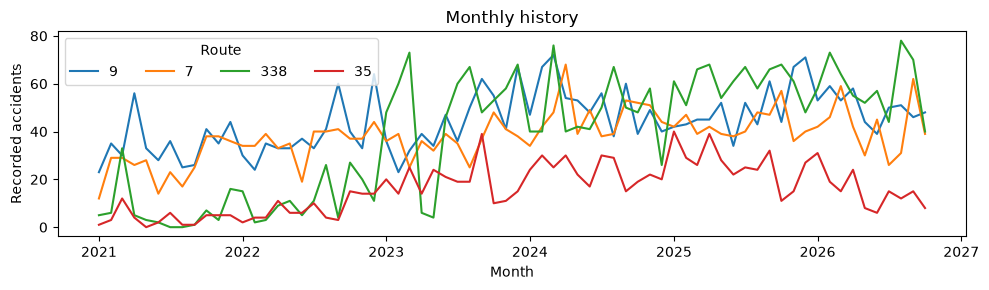

In [12]:
# ดูภาพรวมจำนวนเหตุย้อนหลัง
fig, ax = plt.subplots(figsize=(10, 3))
for route in routes:
    rows = monthly.loc[monthly["route_id"].eq(route)]
    ax.plot(rows["month"].dt.to_timestamp(), rows["count"], label=route.split(":")[-1])
ax.set(xlabel="Month", ylabel="Recorded accidents", title="Monthly history")
ax.legend(title="Route", ncol=4)
plt.tight_layout()
plt.show()

**อ่านกราฟ:** ใน 4 สายทางที่ศึกษา สายทาง 9 มีเหตุที่บันทึกเฉลี่ยสูงสุดประมาณ 44.6 เหตุ/เดือน ส่วนสายทาง 35 เฉลี่ยประมาณ 16 เหตุ/เดือน จำนวนเหตุเปลี่ยนไปตามเวลา จึงควรอัปเดตข้อมูลก่อนพยากรณ์

จำนวนมากกว่าไม่ได้แปลว่าเสี่ยงต่อรถหนึ่งคันมากกว่า เพราะยังไม่รู้ปริมาณจราจร และปี 2569 มีข้อมูลเพียง 10 เดือน

### ข้อมูลที่ใช้ทำนาย
| ชื่อในโค้ด | ความหมาย |
|---|---|
| `lag1`, `lag2`, `lag3` | จำนวนเหตุ 1, 2, 3 เดือนก่อนเดือนเป้าหมาย |
| `mean3` | จำนวนเหตุเฉลี่ย 3 เดือนก่อนหน้า |
| `month_number` | เดือนที่จะทำนาย |
| `route_id` | สายทางที่จะทำนาย |

**Target คือ `count`: จำนวนเหตุของเดือนเป้าหมาย**
เช่น ใช้ประวัติถึงตุลาคม เพื่อทำนายจำนวนเหตุพฤศจิกายน

ข้อมูลเชิงคุณภาพคือสายทาง ส่วนข้อมูลเชิงปริมาณคือจำนวนเหตุย้อนหลัง

มีตัวเลข 4 ตัว และหมวดหมู่ 2 ตัว รวม **6 features** ส่วน 4 สายทางเป็นค่าที่เลือกมาใช้ใน `route_id` ไม่ใช่จำนวน features

In [13]:
def add_features(table):
    table = table.sort_values(["route_id", "month"]).copy()
    for lag in [1, 2, 3]:
        table[f"lag{lag}"] = table.groupby("route_id")["count"].shift(lag)
    table["mean3"] = (table["lag1"] + table["lag2"] + table["lag3"]) / 3
    table["month_number"] = table["month"].dt.month.astype(str)
    return table

In [14]:
# เดือนแรก ๆ ยังไม่มีประวัติครบ 3 เดือน จึงยังไม่ใช้ฝึก
numeric = ["lag1", "lag2", "lag3", "mean3"]
categorical = ["month_number", "route_id"]
features = numeric + categorical
prepared = add_features(monthly).dropna(subset=numeric).copy()
prepared[["month", "count"] + numeric].head(3)

,month,count,lag1,lag2,lag3,mean3
143,2021-04,5,33.0,6.0,5.0,14.666667
144,2021-05,3,5.0,33.0,6.0,14.666667
145,2021-06,2,3.0,5.0,33.0,13.666667


## 3. แบ่งข้อมูลตามเวลา
- **Train ปี 2564–2566:** ข้อมูลเริ่มต้นสำหรับฝึก
- **Validation ปี 2567:** เลือกจาก 3 โมเดล
- **Test ปี 2568–ต.ค. 2569:** ประเมินหลังเลือกแล้ว

**วิธีใหม่:** ก่อนทำนายแต่ละเดือน ให้ฝึกใหม่จากข้อมูลถึงเดือนก่อนหน้า เมื่อเดือนนั้นผ่านไป จึงเพิ่มค่าจริงไว้ฝึกเดือนถัดไป
ตัวอย่าง: ทำนายมีนาคม ใช้ข้อมูลถึงกุมภาพันธ์ ห้ามใช้คำตอบของมีนาคมระหว่างฝึก

In [15]:
train = prepared.loc[prepared["month"].lt(pd.Period("2024-01"))].copy()
validation = prepared.loc[prepared["month"].dt.year.eq(2024)].copy()
test = prepared.loc[prepared["month"].ge(pd.Period("2025-01"))].copy()
print("Train:", len(train), "| Validation:", len(validation), "| Test:", len(test))

Train: 132 | Validation: 48 | Test: 88


### สร้างข้อมูลไม่สมบูรณ์ตามโจทย์อาจารย์
ทำบนสำเนา Train: สร้างค่าว่าง ค่าติดลบ และแถวซ้ำ แล้วแก้ไข
ไม่เปลี่ยน `count` ซึ่งเป็นคำตอบ และไม่ทำให้ Validation/Test เสีย

In [16]:
train_dirty = train.copy()
rng = np.random.default_rng(42)
missing_rows = rng.choice(train_dirty.index, size=5, replace=False)
train_dirty.loc[missing_rows, "lag1"] = np.nan
train_dirty.loc[train_dirty.index[0], "lag2"] = -99
train_dirty = pd.concat([train_dirty, train_dirty.iloc[:3]], ignore_index=True)
print("Train เดิม:", len(train), "แถว | สำเนาที่มีปัญหา:", len(train_dirty), "แถว")

Train เดิม: 132 แถว | สำเนาที่มีปัญหา: 135 แถว


In [17]:
# ลบแถวซ้ำ และเปลี่ยนค่าติดลบที่เป็นไปไม่ได้เป็นค่าว่าง
train_clean = train_dirty.drop_duplicates().copy()
train_clean.loc[train_clean["lag2"].lt(0), "lag2"] = np.nan
print("หลังลบซ้ำ:", len(train_clean), "แถว")
print("ค่าว่างที่จะให้ Pipeline เติม:", int(train_clean[numeric].isna().sum().sum()))

หลังลบซ้ำ: 132 แถว
ค่าว่างที่จะให้ Pipeline เติม: 6


## 4. สร้างโมเดล Regression 3 แบบ
ก่อนฝึก ให้ **Pipeline** เติมค่าว่างด้วยค่ากลางของ Train และแปลงเดือน/สายทางเป็นคอลัมน์ตัวเลข (One-Hot)
Pipeline จะเรียนรู้การแปลงจาก Train เท่านั้น

In [18]:
# clone ที่ใช้ตอนสร้างโมเดล คือการทำสำเนาขั้นตอนให้แต่ละโมเดลเรียนรู้แยกกัน
prepare = ColumnTransformer([
    ("number", SimpleImputer(strategy="median"), numeric),
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical),
])
X_train = train_clean[features]
y_train = train_clean["count"]
X_validation = validation[features]
y_validation = validation["count"]

In [19]:
# 1. Linear Regression: เรียนรู้ความสัมพันธ์แบบเส้นตรง
linear_model = make_pipeline(clone(prepare), LinearRegression())
linear_model.fit(X_train, y_train)
print("ฝึก Linear Regression แล้ว")

ฝึก Linear Regression แล้ว


In [20]:
# 2. Decision Tree: เรียนรู้เป็นเงื่อนไขทีละข้อ
# จำกัดความลึกเพื่อช่วยลดการจำข้อมูลมากเกินไป
tree_model = make_pipeline(clone(prepare),
    DecisionTreeRegressor(max_depth=4, min_samples_leaf=4, random_state=42))
tree_model.fit(X_train, y_train)
print("ฝึก Decision Tree แล้ว")

ฝึก Decision Tree แล้ว


In [21]:
# 3. Random Forest: รวมต้นไม้หลายต้นเพื่อช่วยให้ผลนิ่งขึ้น
forest_model = make_pipeline(clone(prepare),
    RandomForestRegressor(n_estimators=100, max_depth=4, min_samples_leaf=3, random_state=42))
forest_model.fit(X_train, y_train)
print("ฝึก Random Forest แล้ว")

ฝึก Random Forest แล้ว


### เลือกโมเดลจาก Validation แบบฝึกใหม่ทุกเดือน
ใช้ **MAE**: คลาดเคลื่อนเฉลี่ยกี่เหตุ ยิ่งต่ำยิ่งดี
ฟังก์ชันด้านล่างทำซ้ำ 3 อย่าง: ฝึกจากอดีต → ทำนายเดือนนี้ → เพิ่มค่าจริงหลังเดือนนั้นผ่านไป

In [22]:
def predict_each_month(model, history, period):
    records = []
    for month in sorted(period["month"].unique()):
        current = period.loc[period["month"].eq(month)]
        assert history["month"].max() < month  # ใช้เฉพาะอดีต
        updated_model = clone(model)
        updated_model.fit(history[features], history["count"])
        prediction = np.maximum(0, updated_model.predict(current[features]))
        records.append(pd.DataFrame({"month": current["month"],
            "route_id": current["route_id"], "actual": current["count"],
            "prediction": prediction}))
        history = pd.concat([history, current], ignore_index=True)
    return pd.concat(records, ignore_index=True)

In [23]:
models = {"Linear Regression": linear_model, "Decision Tree": tree_model, "Random Forest": forest_model}
validation_rows = []
for name, model in models.items():
    result = predict_each_month(model, train_clean.copy(), validation)
    mae = mean_absolute_error(result["actual"], result["prediction"])
    validation_rows.append({"Model": name, "MAE": mae})
validation_scores = pd.DataFrame(validation_rows).sort_values("MAE")
validation_scores.round(2)

,Model,MAE
2,Random Forest,9.49
0,Linear Regression,9.97
1,Decision Tree,10.13


In [24]:
best_name = validation_scores.iloc[0]["Model"]
best_model = models[best_name]
print("เลือกจาก Validation:", best_name)

เลือกจาก Validation: Random Forest


## 5. ประเมินด้วย Test และเทียบวิธีเดิม
เลือกชนิดโมเดลจาก Validation ก่อน แล้วประเมินทั้ง 3 โมเดลด้วยเดือนเดียวกัน
- **Before:** ฝึกจากปี 2564–2566 ครั้งเดียว แล้วใช้ตลอด
- **After:** ฝึกใหม่ทุกเดือนจากข้อมูลที่มีอยู่จริงก่อนเดือนนั้น

ปี 2567 ผ่านไปแล้วตอนเริ่มประเมินปี 2568 จึงใช้เป็นประวัติฝึกได้ ไม่เปลี่ยนค่าปรับโมเดลตามผล Test

In [25]:
# ตอนเริ่ม Test เราทราบข้อมูลถึงสิ้นปี 2567 แล้ว
history = pd.concat([train_clean, validation], ignore_index=True)
test_rows, predictions_by_model = [], {}
for name, model in models.items():
    old_prediction = np.maximum(0, model.predict(test[features]))
    result = predict_each_month(model, history.copy(), test)
    predictions_by_model[name] = result
    test_rows.append({"Model": name,
        "Before MAE": mean_absolute_error(test["count"], old_prediction),
        "After MAE": mean_absolute_error(result["actual"], result["prediction"])})
test_scores = pd.DataFrame(test_rows)
test_scores["Chosen from validation"] = test_scores["Model"].eq(best_name)
test_scores.round(2)

,Model,Before MAE,After MAE,Chosen from validation
0,Linear Regression,8.32,7.52,False
1,Decision Tree,12.18,8.88,False
2,Random Forest,10.28,8.49,True


In [26]:
# ค่าเฉลี่ย 3 เดือนเป็นวิธีง่าย ๆ สำหรับเทียบกับโมเดล
baseline_mae = mean_absolute_error(test["count"], test["mean3"])
chosen_row = test_scores.loc[test_scores["Model"].eq(best_name)].iloc[0]
print(f"{best_name}: วิธีเดิมผิดเฉลี่ย {chosen_row['Before MAE']:.2f} เหตุ")
print(f"{best_name}: ฝึกใหม่ทุกเดือนผิดเฉลี่ย {chosen_row['After MAE']:.2f} เหตุ")
print(f"ค่าเฉลี่ย 3 เดือนผิดเฉลี่ย {baseline_mae:.2f} เหตุ")
if chosen_row["After MAE"] < baseline_mae:
    print("รอบนี้โมเดลที่เลือกผิดน้อยกว่าค่าเฉลี่ยย้อนหลัง")
else:
    print("รอบนี้ค่าเฉลี่ยย้อนหลังยังดีกว่า จึงยังไม่สรุปว่าโมเดลช่วยเพิ่มประโยชน์")

Random Forest: วิธีเดิมผิดเฉลี่ย 10.28 เหตุ
Random Forest: ฝึกใหม่ทุกเดือนผิดเฉลี่ย 8.49 เหตุ
ค่าเฉลี่ย 3 เดือนผิดเฉลี่ย 7.83 เหตุ
รอบนี้ค่าเฉลี่ยย้อนหลังยังดีกว่า จึงยังไม่สรุปว่าโมเดลช่วยเพิ่มประโยชน์


## 6. ดูกราฟและอ่านผล
กราฟแรกเทียบวิธีเดิมกับการฝึกใหม่ทุกเดือน ส่วนกราฟถัดไปแสดงค่าทำนายแบบใหม่ของหนึ่งสายทาง

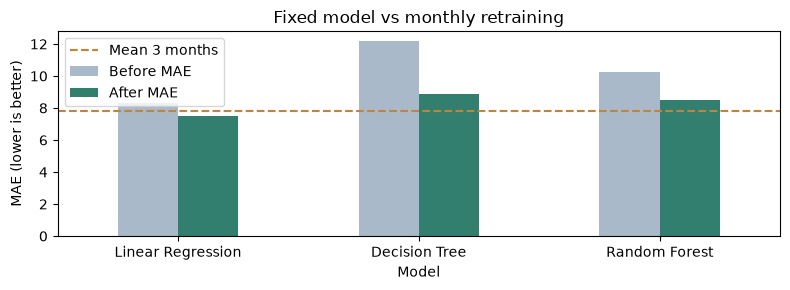

In [27]:
ax = test_scores.set_index("Model")[["Before MAE", "After MAE"]].plot.bar(
    figsize=(8, 3), rot=0, color=["#a9b9c9", "#327f70"])
ax.axhline(baseline_mae, color="#c78332", linestyle="--", label="Mean 3 months")
ax.set(title="Fixed model vs monthly retraining", ylabel="MAE (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()

**อ่านกราฟ:** การฝึกใหม่ทุกเดือนลด MAE ของทั้ง 3 โมเดลในรอบนี้ เช่น Random Forest ลดจาก 10.28 เป็น 8.49 เหตุ แสดงว่าการใช้ประวัติที่อัปเดตช่วยในการทดลองนี้

อย่างไรก็ตาม Random Forest ที่เลือกจาก Validation ยังผิดมากกว่าค่าเฉลี่ย 3 เดือน (7.83 เหตุ) ส่วน Linear Regression ได้ 7.52 เหตุใน Test เป็นข้อค้นพบที่รายงานได้ แต่ไม่ย้อนกลับไปเปลี่ยนการเลือกแล้วอ้างว่าเป็นผลทดสอบใหม่

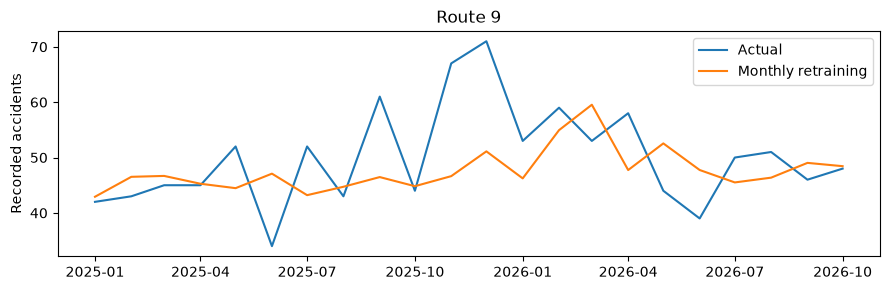

In [28]:
example_route = routes[0]
result = predictions_by_model[best_name]
example = result.loc[result["route_id"].eq(example_route)]
fig, ax = plt.subplots(figsize=(9, 3))
time = example["month"].dt.to_timestamp()
ax.plot(time, example["actual"], label="Actual")
ax.plot(time, example["prediction"], label="Monthly retraining")
ax.set(title="Route " + example_route.split(":")[-1], ylabel="Recorded accidents")
ax.legend()
plt.tight_layout()
plt.show()

**อ่านกราฟ:** ตัวอย่างสายทาง 9 โมเดลตามระดับจำนวนเหตุทั่วไปได้ แต่ยังจับเดือนที่มีเหตุสูงหรือต่ำมากได้ไม่ครบ จึงควรใช้เป็นข้อมูลประกอบการวางแผน ไม่ยึดค่าทำนายเป็นจำนวนที่รับประกัน และกราฟนี้ยังไม่บอกสาเหตุของอุบัติเหตุ

### ลองพยากรณ์เดือนถัดไป
ฝึกชนิดโมเดลที่เลือกจาก Validation ด้วยประวัติทั้งหมดที่รู้แล้ว เพื่อทำนายต่อจากข้อมูลล่าสุด
นี่คือวิธีเดียวกับที่จำลองตอนประเมิน: ฝึกก่อนทำนายแต่ละเดือน และยังไม่มีค่าจริงของเดือนเป้าหมายให้ใช้

In [29]:
# เตรียมแถวใหม่ โดยยังไม่มีคำตอบของเดือนถัดไป
next_month = months.max() + 1
new_rows = pd.DataFrame({"route_id": routes, "month": next_month, "count": np.nan})
future = add_features(pd.concat([monthly, new_rows], ignore_index=True))
future = future.loc[future["month"].eq(next_month)].copy()

In [30]:
# ฝึกชนิดโมเดลที่เลือกใหม่ แล้วทำนายเดือนถัดไป
all_known = pd.concat([train_clean, validation, test], ignore_index=True)
final_model = clone(best_model)
final_model.fit(all_known[features], all_known["count"])
future["forecast"] = np.maximum(0, final_model.predict(future[features]))
future[["route_id", "month", "forecast"]].round({"forecast": 1})

,route_id,month,forecast
282,กรมทางหลวง:338,2026-11,52.5
283,กรมทางหลวง:35,2026-11,12.5
281,กรมทางหลวง:7,2026-11,43.7
280,กรมทางหลวง:9,2026-11,47.4


### สรุปสั้น ๆ
- เราทำนาย **จำนวนเหตุที่บันทึกในเดือนหน้า** และฝึกใหม่เมื่อมีข้อมูลเดือนล่าสุด
- รอบนี้คง 6 features และค่าปรับเดิมไว้ เพื่อดูผลของการเปลี่ยนวิธีฝึกก่อน
- ต้องเทียบกับค่าเฉลี่ยย้อนหลังด้วย ถ้าโมเดลผิดมากกว่า ก็ยังไม่ถือว่าช่วยเพิ่มประโยชน์
- จำนวนเหตุไม่ได้บอกความเสี่ยงต่อรถหนึ่งคัน เพราะไม่มีปริมาณจราจร
- ปี 2569 ไม่มีรหัสเหตุ จึงยังอาจตรวจรายงานซ้ำได้ไม่ครบ และวันที่ผิดบางรายการยังมีข้อจำกัด
- ข้อมูลนี้เคยถูกสำรวจแล้ว ผลเป็นการประเมินย้อนหลัง ไม่ใช่ Test ใหม่อิสระ

### อ้างอิง
- ข้อมูล: [กระทรวงคมนาคม / TRAMS](https://datagov.mot.go.th/dataset/roadaccident) ปี 2564–2569
- ข้อกำหนดงาน: `CS245_69_Term Porject (1).pdf`
- แนวทางเรียงเนื้อหา: `Students’_Social_Media_Addiction_Prediction.ipynb` ของรุ่นพี่

ก่อนส่ง: เติม Section หมายเลขกลุ่ม และหน้าที่สมาชิกตามจริง แล้วเปลี่ยนชื่อไฟล์ตามโจทย์